In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict,Literal


### now what we want for quadratic equation ax2+bx+c right so we want 3 thing a,b,c then an attribute where we will save our quadratic equation and discriminant (d) and one more attribute result 

In [2]:
class QuadState(TypedDict):
    a:int
    b:int
    c:int

    equation: str
    discriminant: str
    result: str

    

In [10]:
def show_equation(state:QuadState):
    equation=f'{state['a']}x2{state['b']}x{state['c']}'
    return {'equation':equation}

def calculate_discriminant(state:QuadState):
    discriminant=state['b']**2-4*state['a']*state['c']
    return {'discriminant':discriminant}

def real_roots(state:QuadState):
    d=state['discriminant']
    r1=(-state['b']+d**0.5)/(2*state['a'])
    r2=(-state['b']-d**0.5)/(2*state['a'])
    return {'result':f'The roots are {r1} and {r2}'}

def repeated_roots(state:QuadState):
    r=-state['b']/(2*state['a'])
    return {'result':f'The root is {r}'}

def no_real_roots(state:QuadState):
    result='No real roots'
    return {'result':result}

def check_condition(state:QuadState) -> Literal['real_roots','repeated_roots','no_real_roots']:
    d=state['discriminant']
    if d>0:
        return 'real_roots'
    elif d==0:
        return 'repeated_roots'
    else:
        return 'no_real_roots'


In [12]:
graph=StateGraph(QuadState)

graph.add_node('show_quation',show_equation)
graph.add_node('calculate_discriminant',calculate_discriminant)
graph.add_node('real_roots',real_roots)
graph.add_node('repeated_roots',repeated_roots)
graph.add_node('no_real_roots',no_real_roots)

graph.add_edge(START,'show_quation')
graph.add_edge('show_quation', 'calculate_discriminant')

graph.add_conditional_edges('calculate_discriminant',check_condition)
graph.add_edge('real_roots',END)
graph.add_edge('repeated_roots',END)
graph.add_edge('no_real_roots',END)

workflow=graph.compile()


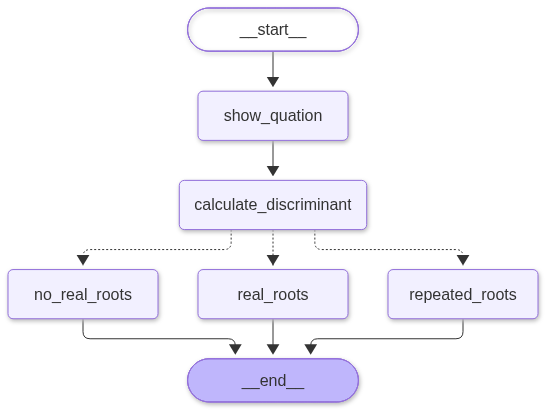

In [13]:
workflow

In [15]:
initial_state={
    'a':2,
    'b':4,
    'c':2
}
workflow.invoke(initial_state)

{'a': 2,
 'b': 4,
 'c': 2,
 'equation': '2x24x2',
 'discriminant': 0,
 'result': 'The root is -1.0'}